# Run 3 — Fake-PD-Only (Zero-Shot) on the 17-Patient Test Set

Every Run 1 / Run 2 experiment trained on fake PD **plus 13 real PD patients**. In that mixed
regime the model has already seen the real distribution, so the fake→real gap is only ~0.02 and
each idea was competing for ~0.01 against a 0.0226 noise floor — undetectable by construction.

Run 3 removes real PD from training **and** from checkpoint selection. From
`docs/DEBUG_HANDOFF.md` §5.1 / §17.7:

| Regime | Real-PD Dice |
|---|---|
| fake-only (`run_002_v2`, best) | 0.695 |
| fake + 15 real (`v7_mixed`) | 0.781 |

That reopens a **0.09–0.15 domain gap** — 4–6× the old floor — so an idea that closes even a
third of it is now measurable.

**Two things differ from the Phase 5 notebooks and must not be carried over:**

1. **The 0.0226 noise floor does NOT apply here.** It was measured in the mixed regime. Section 2
   below measures the Run 3 floor directly from `base` seed42 vs seed7, and every verdict uses
   that measured value.
2. **`history.csv` has a different schema.** Selection is `dice_fake_va_smooth` (a 3-epoch
   trailing mean of fake-val Dice — what `ckpt_best.pth` was actually chosen on). `dice_real_va_diag`
   is a *diagnostic only*: real PD never touched a gradient or the selection rule.

In [13]:
import os
import glob
import re
import csv

import numpy as np
import pandas as pd
import nibabel as nib
import SimpleITK as sitk
import matplotlib.pyplot as plt
from scipy.ndimage import zoom

In [14]:
BASE = "/Users/anshikabajpai/Desktop/github/RegGAN_domain_adaptation_v2"
RES  = f"{BASE}/results"
RUNS = f"{BASE}/segmentation_runs"

GT_DIR_D1  = "/Users/anshikabajpai/Desktop/AImed-lab/SEGMENTATIONS/PD-segmentations-final"
GT_DIR_NEW = "/Users/anshikabajpai/Downloads/final-segmentations"   # NOT "segmentations" -- landmine

# label -> (17pt prediction dir, run dir holding history.csv)
BASE_LABEL = "base seed42 (fake-only reference)"
SEED7_LABEL = "base seed7 (noise-floor pair)"

RUNS_INFO = {
    BASE_LABEL:                 (f"{RES}/real_pd_predictions_fakeonly_base_seed42_17pt", f"{RUNS}/run_fakeonly_base_seed42"),
    SEED7_LABEL:                (f"{RES}/real_pd_predictions_fakeonly_base_seed7_17pt",  f"{RUNS}/run_fakeonly_base_seed7"),
    "A3-none (control)":        (f"{RES}/real_pd_predictions_fakeonly_a3_none_17pt",     f"{RUNS}/run_fakeonly_a3_none_seed42"),
    "A3-up (end slices x2)":    (f"{RES}/real_pd_predictions_fakeonly_a3_up_17pt",       f"{RUNS}/run_fakeonly_a3_up_seed42"),
    "A3-down (end slices x0.3)":(f"{RES}/real_pd_predictions_fakeonly_a3_down_17pt",     f"{RUNS}/run_fakeonly_a3_down_seed42"),
    "E1 (position channel)":    (f"{RES}/real_pd_predictions_fakeonly_e1_17pt",          f"{RUNS}/run_fakeonly_e1_seed42"),
    "E2 (FiLM gating)":         (f"{RES}/real_pd_predictions_fakeonly_e2_17pt",          f"{RUNS}/run_fakeonly_e2_seed42"),
    "G2 (rim-darkness loss)":   (f"{RES}/real_pd_predictions_fakeonly_g2_17pt",          f"{RUNS}/run_fakeonly_g2_seed42"),
    "D (shape prior)":          (f"{RES}/real_pd_predictions_fakeonly_d_17pt",           f"{RUNS}/run_fakeonly_d_seed42"),
}
# Paths match the CKPT=/OUT_DIR= lines in slurm_files/fakeonly_*.sh and
# slurm_files/infer_fakeonly_*_17pt.sh -- not retyped from memory.

# Reference points from the MIXED regime, for context only. Never a Run 3 baseline.
MIXED_REPLICA_TEST   = 0.7780
MIXED_CROPSEQ_TEST   = 0.8057
MIXED_NOISE_FLOOR    = 0.0226

D1_PATIENTS = [
    "AC0D5A4D78B628", "AC0D7BF72F7712", "AC0D3459553205", "AC14D3737C0482",
    "AC19E7C19827FF", "AC149BC218E75C", "AC111633B463BB", "AC13300201B926",
    "AC12026D14291F", "AC13637DA25399",
]
NEW_PATIENTS = [
    "AC000550763509", "AC005135D3495B", "AC04433E37DB66", "AC056ADCE8BE28",
    "AC07607B9E5295", "AC0D1A9818A6FC", "AC0F11041F5180",
]
ALL_PATIENTS = D1_PATIENTS + NEW_PATIENTS
VAL_PATIENTS = ["AC0CE315D5758B", "AC0CEE9C24F2B7"]   # diagnostic only in Run 3

print(f"Test set: {len(ALL_PATIENTS)} patients (D1={len(D1_PATIENTS)}, new={len(NEW_PATIENTS)})")
print(f"Run 3: real PD never used for training or checkpoint selection.")

Test set: 17 patients (D1=10, new=7)
Run 3: real PD never used for training or checkpoint selection.


## Helpers — identical conventions to the Phase 5 notebooks

In [15]:
def get_pid(fname):
    m = re.match(r"(AC[A-F0-9]+)", os.path.basename(fname), re.IGNORECASE)
    return m.group(1) if m else None

def patients_in_dir(directory):
    files = glob.glob(os.path.join(directory, "*.nii.gz"))
    return {get_pid(f): f for f in files if get_pid(f)}

def load_vol(path):
    return np.asarray(nib.load(path).get_fdata())

def load_nrrd_binary(path):
    """Verbatim from analysis_phase5_novel_approaches_17patients.ipynb."""
    img = sitk.ReadImage(path)
    arr = sitk.GetArrayFromImage(img)
    if arr.ndim == 4:
        arr = (arr.max(axis=0) > 0).astype(np.uint8)
        out = sitk.GetImageFromArray(arr)
        try:
            comp = sitk.VectorIndexSelectionCast(img, 0)
            out.CopyInformation(comp)
        except Exception:
            out.SetSpacing(img.GetSpacing()[:3]); out.SetOrigin(img.GetOrigin()[:3])
            out.SetDirection(img.GetDirection()[:9])
    else:
        arr = (arr > 0).astype(np.uint8)
        out = sitk.GetImageFromArray(arr)
        out.CopyInformation(img)
    try:
        out = sitk.DICOMOrient(out, "RAS")
    except Exception:
        pass
    sp  = out.GetSpacing()
    arr = sitk.GetArrayFromImage(out).astype(np.float32).transpose(2, 1, 0)
    fa  = float(sp[1]) / min(sp[1], sp[2])
    fs  = float(sp[2]) / min(sp[1], sp[2])
    if abs(fa - 1.0) > 0.02 or abs(fs - 1.0) > 0.02:
        arr = zoom(arr, (1.0, fa, fs), order=0)
    _, n_A, n_S = arr.shape
    if n_A != 384 or n_S != 384:
        arr = zoom(arr, (1.0, 384 / n_A, 384 / n_S), order=0)
    return (arr > 0.5).astype(bool)

def merge_meniscus(pred):
    return (pred > 0).astype(bool)

def dice_score(pred_bin, gt_bin):
    if pred_bin.shape != gt_bin.shape:
        raise ValueError(f"shape mismatch: pred {pred_bin.shape} vs gt {gt_bin.shape} "
                         f"-- refusing to silently resample, fix the source")
    inter = (pred_bin & gt_bin).sum()
    denom = pred_bin.sum() + gt_bin.sum()
    return float(2 * inter / denom) if denom > 0 else 1.0

## Section 1 — 17-patient test Dice

This is the zero-shot number: the checkpoint never saw a real-PD label during training **or**
selection, and these 17 patients were never seen at all.

In [16]:
gt_masks = {}
for pid in ALL_PATIENTS:
    hits = (glob.glob(os.path.join(GT_DIR_D1,  f"{pid}*.seg.nrrd")) or
            glob.glob(os.path.join(GT_DIR_NEW, f"{pid}*.seg.nrrd")))
    if hits:
        gt_masks[pid] = hits[0]
    else:
        print(f"WARNING: No GT for {pid}")
print(f"GT masks found: {len(gt_masks)}/{len(ALL_PATIENTS)}\n")

preds_by_run = {}
for label, (pred_dir, _) in RUNS_INFO.items():
    d = patients_in_dir(pred_dir) if os.path.isdir(pred_dir) else {}
    preds_by_run[label] = d
    status = f"{len(d)}/{len(ALL_PATIENTS)}" if d else "NOT FOUND -- run inference / pull results first"
    print(f"{label:<30}: {status}")

GT masks found: 17/17

base seed42 (fake-only reference): 17/17
base seed7 (noise-floor pair) : 17/17
A3-none (control)             : 17/17
A3-up (end slices x2)         : 17/17
A3-down (end slices x0.3)     : 17/17
E1 (position channel)         : 17/17
E2 (FiLM gating)              : 17/17
G2 (rim-darkness loss)        : 17/17
D (shape prior)               : 17/17


In [17]:
rows = []
for pid in ALL_PATIENTS:
    if pid not in gt_masks:
        continue
    gt_bin = load_nrrd_binary(gt_masks[pid])
    row = {"patient": pid, "cohort": "D1" if pid in D1_PATIENTS else "new"}
    for label, preds in preds_by_run.items():
        row[label] = (dice_score(merge_meniscus(load_vol(preds[pid])), gt_bin)
                      if pid in preds else float("nan"))
    rows.append(row)

df = pd.DataFrame(rows)
means = df[list(RUNS_INFO.keys())].mean()
print("MEAN 17pt test Dice per run (fake-only / zero-shot):")
print(means.round(4).to_string())
df

MEAN 17pt test Dice per run (fake-only / zero-shot):
base seed42 (fake-only reference)    0.6725
base seed7 (noise-floor pair)        0.6468
A3-none (control)                    0.6410
A3-up (end slices x2)                0.6638
A3-down (end slices x0.3)            0.6421
E1 (position channel)                0.6917
E2 (FiLM gating)                     0.6476
G2 (rim-darkness loss)               0.6811
D (shape prior)                      0.6780


,patient,cohort,base seed42 (fake-only reference),base seed7 (noise-floor pair),A3-none (control),A3-up (end slices x2),A3-down (end slices x0.3),E1 (position channel),E2 (FiLM gating),G2 (rim-darkness loss),D (shape prior)
0,AC0D5A4D78B628,D1,0.644526,0.603920,0.590081,0.575152,0.571972,0.671063,0.628866,0.600505,0.606580
1,AC0D7BF72F7712,D1,0.594555,0.604503,0.612525,0.625149,0.624937,0.649739,0.566518,0.611554,0.658113
2,AC0D3459553205,D1,0.658481,0.615898,0.642108,0.628253,0.628883,0.684951,0.655628,0.675392,0.688321
3,AC14D3737C0482,D1,0.616549,0.451994,0.624208,0.653369,0.590898,0.619123,0.520218,0.588169,0.614530
4,AC19E7C19827FF,D1,0.681933,0.642191,0.659513,0.641072,0.649956,0.693226,0.664163,0.682052,0.662774
5,AC149BC218E75C,D1,0.676568,0.637026,0.616755,0.671500,0.597993,0.700092,0.611949,0.644369,0.695379
6,AC111633B463BB,D1,0.738413,0.751190,0.725418,0.718374,0.713511,0.774551,0.745087,0.765995,0.733369
7,AC13300201B926,D1,0.697884,0.681712,0.693093,0.675049,0.695415,0.685481,0.616418,0.722909,0.695965
8,AC12026D14291F,D1,0.681835,0.680473,0.686652,0.659197,0.618028,0.710713,0.680638,0.706053,0.685428
9,AC13637DA25399,D1,0.690194,0.684358,0.659689,0.716574,0.646556,0.734573,0.723282,0.683856,0.712679


## Section 2 — Measure the Run 3 noise floor

The mixed-regime floor (0.0226) came from seed42-vs-seed7 of the *mixed* replica recipe and does
not transfer to this regime. Here it is re-measured the same way — **per-patient max |Δ| between
the two `base` seeds** — and that measured value is what every verdict below uses.

Expect it to be **larger** than 0.0226: with no real-PD anchor, training is less constrained.

In [18]:
if df[BASE_LABEL].notna().any() and df[SEED7_LABEL].notna().any():
    pair = df[["patient", "cohort", BASE_LABEL, SEED7_LABEL]].dropna().copy()
    pair["abs_delta"] = (pair[BASE_LABEL] - pair[SEED7_LABEL]).abs()
    NOISE_FLOOR = float(pair["abs_delta"].max())
    print(f"seed42 mean = {pair[BASE_LABEL].mean():.4f}   seed7 mean = {pair[SEED7_LABEL].mean():.4f}")
    print(f"per-patient max |delta| = {NOISE_FLOOR:.4f}   <-- RUN 3 NOISE FLOOR")
    print(f"per-patient mean |delta| = {pair['abs_delta'].mean():.4f}")
    print(f"\n(mixed-regime floor was {MIXED_NOISE_FLOOR:.4f} -- shown for contrast, NOT used here)")
    display(pair.sort_values("abs_delta", ascending=False).round(4))
else:
    NOISE_FLOOR = float("nan")
    print("Both base seeds are needed to measure the Run 3 floor.")
    print("Missing:", [l for l in (BASE_LABEL, SEED7_LABEL) if df[l].isna().all()])
    print("\nNothing below can be judged until this is measured -- do NOT fall back to 0.0226.")

seed42 mean = 0.6725   seed7 mean = 0.6468
per-patient max |delta| = 0.1646   <-- RUN 3 NOISE FLOOR
per-patient mean |delta| = 0.0439

(mixed-regime floor was 0.0226 -- shown for contrast, NOT used here)


,patient,cohort,base seed42 (fake-only reference),base seed7 (noise-floor pair),abs_delta
3,AC14D3737C0482,D1,0.6165,0.4520,0.1646
14,AC07607B9E5295,new,0.7435,0.5817,0.1618
16,AC0F11041F5180,new,0.6056,0.7218,0.1163
13,AC056ADCE8BE28,new,0.6432,0.5737,0.0694
2,AC0D3459553205,D1,0.6585,0.6159,0.0426
0,AC0D5A4D78B628,D1,0.6445,0.6039,0.0406
4,AC19E7C19827FF,D1,0.6819,0.6422,0.0397
5,AC149BC218E75C,D1,0.6766,0.6370,0.0395
7,AC13300201B926,D1,0.6979,0.6817,0.0162
6,AC111633B463BB,D1,0.7384,0.7512,0.0128


## Section 3 — Training-time metrics from `history.csv`

Run 3 schema. `dice_fake_va_smooth` is the selection criterion (3-epoch trailing mean), so the
"best epoch" here is the epoch `ckpt_best.pth` was actually saved at — not the raw argmax.
`dice_real_va_diag` is logged for information only and never influenced anything.

In [19]:
def best_epoch_fakeonly(history_path):
    """Selects the row that maximises dice_fake_va_smooth -- the criterion the
    training loop itself used. Falls back to raw dice_fake_va for any run written
    with --select_smooth 1."""
    if not os.path.exists(history_path):
        return None
    rows = list(csv.DictReader(open(history_path)))
    if not rows:
        return None
    key = "dice_fake_va_smooth" if "dice_fake_va_smooth" in rows[0] else "dice_fake_va"
    best = max(rows, key=lambda r: float(r[key]))
    out = {
        "best_epoch":   int(best["epoch"]),
        "n_epochs":     len(rows),
        "dice_fake_va": float(best["dice_fake_va"]),
        "dice_fake_tr": float(best["dice_fake_tr"]),
        "smooth":       float(best[key]),
        "gap_fake":     float(best["gap_fake"]),
    }
    if "dice_real_va_diag" in best:
        out["real_va_diag"] = float(best["dice_real_va_diag"])
    for c in ("pos_wnorm", "rim_frac", "area_frac"):
        if c in best:
            out[c] = float(best[c])
    return out

val_rows = []
for label, (_, run_dir) in RUNS_INFO.items():
    info = best_epoch_fakeonly(os.path.join(run_dir, "history.csv"))
    if info is None:
        print(f"{label:<30}: history.csv not found under {run_dir}")
        continue
    val_rows.append({"run": label, **info})

val_df = pd.DataFrame(val_rows)
val_df

,run,best_epoch,n_epochs,dice_fake_va,dice_fake_tr,smooth,gap_fake,real_va_diag,pos_wnorm,rim_frac,area_frac
0,base seed42 (fake-only reference),26,37,0.77159,0.89958,0.77204,0.12799,0.63565,NaN,NaN,NaN
1,base seed7 (noise-floor pair),17,28,0.78097,0.88357,0.78082,0.10260,0.66776,NaN,NaN,NaN
2,A3-none (control),19,30,0.77541,0.88055,0.77394,0.10514,0.65707,NaN,NaN,NaN
3,A3-up (end slices x2),20,31,0.76958,0.87661,0.77170,0.10702,0.65867,NaN,NaN,NaN
4,A3-down (end slices x0.3),30,41,0.76930,0.89806,0.76877,0.12877,0.68769,NaN,NaN,NaN
5,E1 (position channel),32,43,0.77977,0.90527,0.77782,0.12551,0.66571,0.110320,NaN,NaN
6,E2 (FiLM gating),15,26,0.77611,0.87881,0.77640,0.10270,0.64210,0.783571,NaN,NaN
7,G2 (rim-darkness loss),23,34,0.77945,0.89293,0.77723,0.11349,0.63602,NaN,0.009,NaN
8,D (shape prior),17,28,0.77912,0.88518,0.77756,0.10605,0.61866,NaN,NaN,0.0


In [20]:
# Did the domain gap actually close? fake-val vs the real-PD diagnostic, same checkpoint.
if not val_df.empty and "real_va_diag" in val_df.columns:
    g = val_df[["run", "dice_fake_va", "real_va_diag"]].copy()
    g["fake_minus_real"] = (g["dice_fake_va"] - g["real_va_diag"]).round(4)
    print("Domain gap per run (fake val - real val). Smaller = the idea transferred better.\n")
    display(g.round(4))
    print("Mixed-regime reference: the gap there was ~0.02 because real PD was in training.")
    print("A Run 3 gap much larger than that is expected and is the thing these ideas target.")

Domain gap per run (fake val - real val). Smaller = the idea transferred better.



,run,dice_fake_va,real_va_diag,fake_minus_real
0,base seed42 (fake-only reference),0.7716,0.6357,0.1359
1,base seed7 (noise-floor pair),0.7810,0.6678,0.1132
2,A3-none (control),0.7754,0.6571,0.1183
3,A3-up (end slices x2),0.7696,0.6587,0.1109
4,A3-down (end slices x0.3),0.7693,0.6877,0.0816
5,E1 (position channel),0.7798,0.6657,0.1141
6,E2 (FiLM gating),0.7761,0.6421,0.1340
7,G2 (rim-darkness loss),0.7794,0.6360,0.1434
8,D (shape prior),0.7791,0.6187,0.1605


Mixed-regime reference: the gap there was ~0.02 because real PD was in training.
A Run 3 gap much larger than that is expected and is the thing these ideas target.


## Section 4 — Ranking vs the fake-only baseline, against the **measured** floor

In [21]:
if np.isnan(NOISE_FLOOR):
    print("Run 3 noise floor not measured yet (Section 2) -- ranking withheld.")
else:
    rank_rows = []
    for label in RUNS_INFO:
        if label == SEED7_LABEL or label not in means.index or np.isnan(means[label]):
            continue
        delta = means[label] - means[BASE_LABEL]
        rank_rows.append({
            "run": label,
            "test_17pt_mean": round(means[label], 4),
            "delta_vs_base": round(delta, 4),
            "above_noise_floor": abs(delta) > NOISE_FLOOR,
            "direction": ("real gain" if delta > NOISE_FLOOR else
                          "real loss" if delta < -NOISE_FLOOR else
                          "noise / no effect"),
        })
    rank_df = pd.DataFrame(rank_rows).sort_values("test_17pt_mean", ascending=False).reset_index(drop=True)
    print(f"Baseline: {BASE_LABEL} = {means[BASE_LABEL]:.4f}   |   MEASURED floor = ±{NOISE_FLOOR:.4f}")
    display(rank_df)

    # A3 up/down read against their own control, not the plain baseline:
    ctrl = "A3-none (control)"
    if ctrl in means.index and not np.isnan(means[ctrl]):
        print(f"\nA3 secondary read -- vs its own control ({ctrl} = {means[ctrl]:.4f}):")
        for lab in ["A3-up (end slices x2)", "A3-down (end slices x0.3)"]:
            if lab in means.index and not np.isnan(means[lab]):
                d = means[lab] - means[ctrl]
                verdict = ("real gain" if d > NOISE_FLOOR else
                           "real loss" if d < -NOISE_FLOOR else "noise / no effect")
                print(f"  {lab:<30}: {means[lab]:.4f}  (delta {d:+.4f}, {verdict})")

Baseline: base seed42 (fake-only reference) = 0.6725   |   MEASURED floor = ±0.1646


,run,test_17pt_mean,delta_vs_base,above_noise_floor,direction
0,E1 (position channel),0.6917,0.0192,False,noise / no effect
1,G2 (rim-darkness loss),0.6811,0.0086,False,noise / no effect
2,D (shape prior),0.6780,0.0055,False,noise / no effect
3,base seed42 (fake-only reference),0.6725,0.0000,False,noise / no effect
4,A3-up (end slices x2),0.6638,-0.0087,False,noise / no effect
5,E2 (FiLM gating),0.6476,-0.0249,False,noise / no effect
6,A3-down (end slices x0.3),0.6421,-0.0304,False,noise / no effect
7,A3-none (control),0.6410,-0.0315,False,noise / no effect



A3 secondary read -- vs its own control (A3-none (control) = 0.6410):
  A3-up (end slices x2)         : 0.6638  (delta +0.0228, noise / no effect)
  A3-down (end slices x0.3)     : 0.6421  (delta +0.0011, noise / no effect)


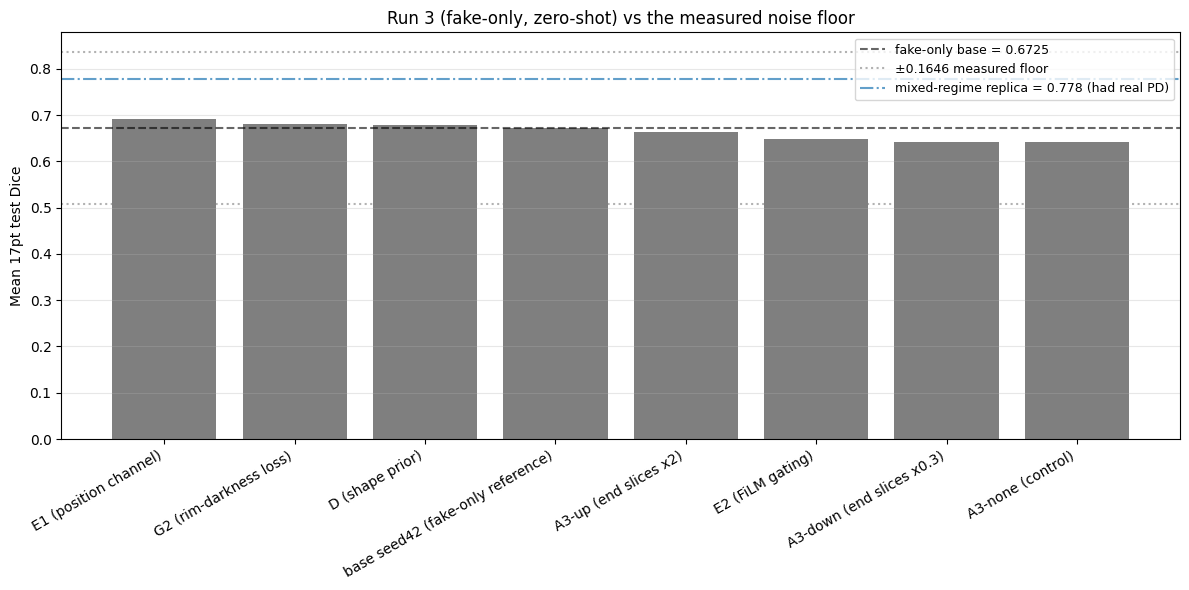

In [22]:
if not np.isnan(NOISE_FLOOR):
    fig, ax = plt.subplots(figsize=(12, 6))
    colors = {"real gain": "tab:green", "real loss": "tab:red", "noise / no effect": "tab:gray"}
    ax.bar(rank_df["run"], rank_df["test_17pt_mean"], color=[colors[d] for d in rank_df["direction"]])
    b = means[BASE_LABEL]
    ax.axhline(b, linestyle="--", color="black", alpha=.6, label=f"fake-only base = {b:.4f}")
    ax.axhline(b + NOISE_FLOOR, linestyle=":", color="gray", alpha=.6)
    ax.axhline(b - NOISE_FLOOR, linestyle=":", color="gray", alpha=.6,
               label=f"±{NOISE_FLOOR:.4f} measured floor")
    ax.axhline(MIXED_REPLICA_TEST, linestyle="-.", color="tab:blue", alpha=.7,
               label=f"mixed-regime replica = {MIXED_REPLICA_TEST} (had real PD)")
    ax.set_ylabel("Mean 17pt test Dice")
    ax.set_title("Run 3 (fake-only, zero-shot) vs the measured noise floor")
    ax.set_xticks(range(len(rank_df)))
    ax.set_xticklabels(rank_df["run"], rotation=30, ha="right")
    ax.legend(fontsize=9); ax.grid(axis="y", alpha=.3)
    plt.tight_layout(); plt.show()

## Section 5 — How much of the domain gap did each idea close?

The headline framing for a zero-shot claim. `0%` = no better than fake-only training;
`100%` = matches the mixed-regime model that actually trained on 13 real patients.

In [23]:
if not np.isnan(NOISE_FLOOR) and not np.isnan(means[BASE_LABEL]):
    span = MIXED_REPLICA_TEST - means[BASE_LABEL]
    print(f"Zero-shot baseline {means[BASE_LABEL]:.4f}  ->  mixed-regime replica {MIXED_REPLICA_TEST:.4f}")
    print(f"Domain gap to close: {span:.4f}\n")
    if span <= 0:
        print("Baseline already matches/exceeds the mixed model -- gap framing does not apply.")
    else:
        close_rows = []
        for label in RUNS_INFO:
            if label == SEED7_LABEL or label not in means.index or np.isnan(means[label]):
                continue
            d = means[label] - means[BASE_LABEL]
            close_rows.append({
                "run": label,
                "test_17pt": round(means[label], 4),
                "delta_vs_base": round(d, 4),
                "pct_of_gap_closed": round(100 * d / span, 1),
                "beats_floor": abs(d) > NOISE_FLOOR,
            })
        display(pd.DataFrame(close_rows).sort_values("pct_of_gap_closed", ascending=False).reset_index(drop=True))

Zero-shot baseline 0.6725  ->  mixed-regime replica 0.7780
Domain gap to close: 0.1055



,run,test_17pt,delta_vs_base,pct_of_gap_closed,beats_floor
0,E1 (position channel),0.6917,0.0192,18.2,False
1,G2 (rim-darkness loss),0.6811,0.0086,8.1,False
2,D (shape prior),0.6780,0.0055,5.2,False
3,base seed42 (fake-only reference),0.6725,0.0000,0.0,False
4,A3-up (end slices x2),0.6638,-0.0087,-8.3,False
5,E2 (FiLM gating),0.6476,-0.0249,-23.6,False
6,A3-down (end slices x0.3),0.6421,-0.0304,-28.9,False
7,A3-none (control),0.6410,-0.0315,-29.9,False


## Section 6 — Cohort split (10 original D1 patients vs 7 newer)

The two cohorts were annotated at different times. A gain that appears on only one of them is
more likely annotation drift than a modelling effect — this caught three sign-flips in the
crop+sequence arm.

In [24]:
labels = [l for l in RUNS_INFO if not df[l].isna().all()]
d1, new = df[df.cohort == "D1"], df[df.cohort == "new"]
out = []
for l in labels:
    out.append({
        "run": l,
        "D1_mean":      round(d1[l].mean(), 4),
        "new_mean":     round(new[l].mean(), 4),
        "all_17":       round(df[l].mean(), 4),
        "D1_minus_new": round(d1[l].mean() - new[l].mean(), 4),
    })
cohort_df = pd.DataFrame(out)
print(f"D1 = {len(d1)} patients, new = {len(new)} patients\n")
display(cohort_df)

if BASE_LABEL in labels and not np.isnan(NOISE_FLOOR):
    b_d1, b_new = d1[BASE_LABEL].mean(), new[BASE_LABEL].mean()
    print(f"\nDelta vs base per cohort (floor ±{NOISE_FLOOR:.4f}):")
    for _, r in cohort_df.iterrows():
        if r["run"] in (BASE_LABEL, SEED7_LABEL):
            continue
        dd1, dnew = r["D1_mean"] - b_d1, r["new_mean"] - b_new
        flip = "   <-- SIGN FLIP between cohorts" if (dd1 > 0) != (dnew > 0) else ""
        print(f"  {r['run']:<30} D1 {dd1:+.4f}   new {dnew:+.4f}{flip}")

D1 = 10 patients, new = 7 patients



,run,D1_mean,new_mean,all_17,D1_minus_new
0,base seed42 (fake-only reference),0.6681,0.6789,0.6725,-0.0108
1,base seed7 (noise-floor pair),0.6353,0.6633,0.6468,-0.0280
2,A3-none (control),0.6510,0.6267,0.6410,0.0243
3,A3-up (end slices x2),0.6564,0.6745,0.6638,-0.0181
4,A3-down (end slices x0.3),0.6338,0.6539,0.6421,-0.0201
5,E1 (position channel),0.6924,0.6908,0.6917,0.0015
6,E2 (FiLM gating),0.6413,0.6567,0.6476,-0.0154
7,G2 (rim-darkness loss),0.6681,0.6997,0.6811,-0.0316
8,D (shape prior),0.6753,0.6819,0.6780,-0.0066



Delta vs base per cohort (floor ±0.1646):
  A3-none (control)              D1 -0.0171   new -0.0522
  A3-up (end slices x2)          D1 -0.0117   new -0.0044
  A3-down (end slices x0.3)      D1 -0.0343   new -0.0250
  E1 (position channel)          D1 +0.0243   new +0.0119
  E2 (FiLM gating)               D1 -0.0268   new -0.0222
  G2 (rim-darkness loss)         D1 +0.0000   new +0.0208
  D (shape prior)                D1 +0.0072   new +0.0030
